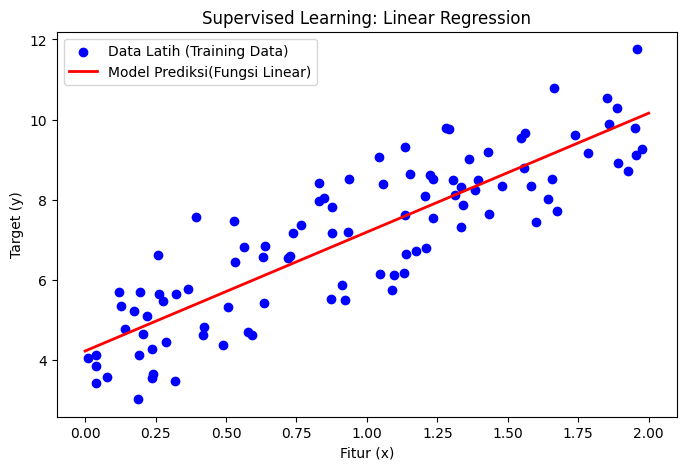

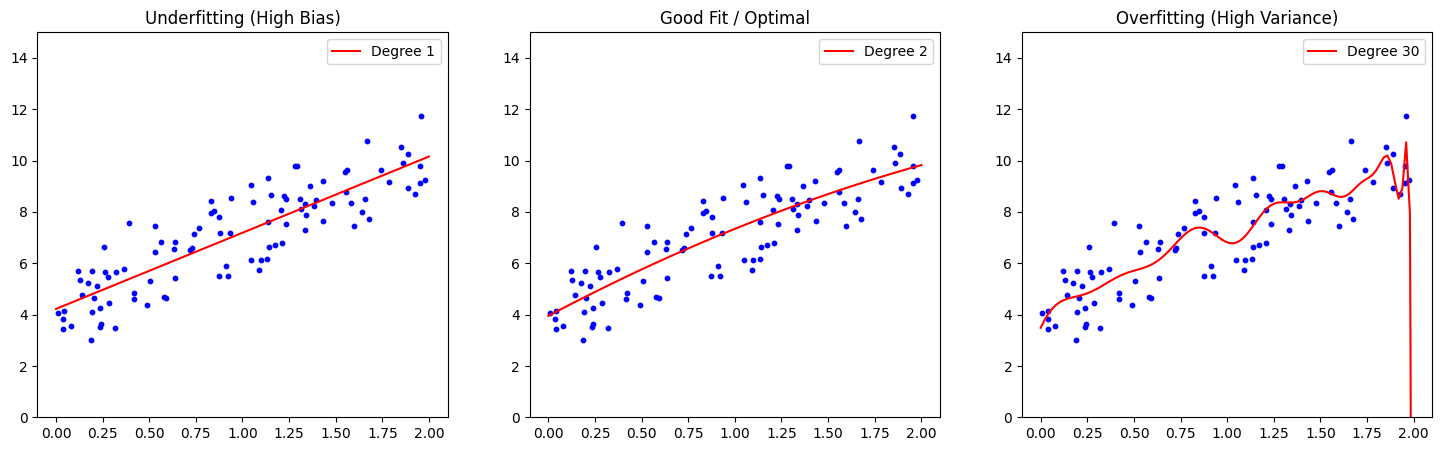

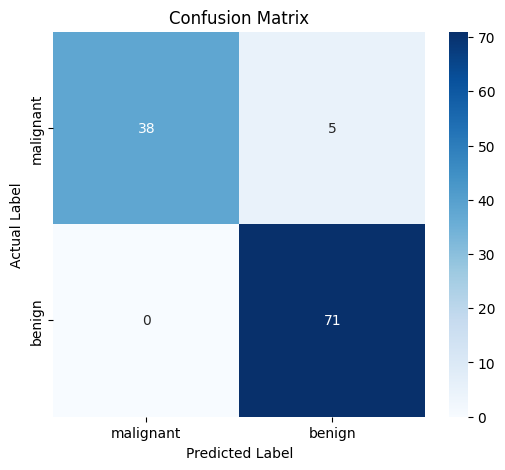

True Positive (TP): 71
True Negative (TN): 38
False Positive (FP): 5
False Negative (FN): 0
------------------------------
Accuracy : 0.9561
Precision : 0.9342
Recall : 1.0000
Specificity: 0.8837


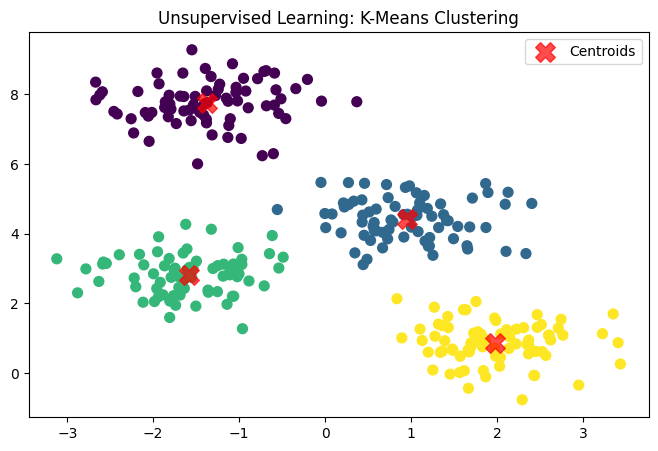

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Membuat data dummy (Contoh: Umur vs Penghasilan)
# X = Fitur (misal: Umur), y = Target (misal: Income)
np.random.seed(0)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1) # y = 4 + 3x + noise

# 2. Melatih Model Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# 3. Visualisasi
X_new = np.array([[0], [2]])
y_predict = lin_reg.predict(X_new)
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Data Latih (Training Data)')
plt.plot(X_new, y_predict, color='red', linewidth=2, label='Model Prediksi(Fungsi Linear)')
plt.xlabel("Fitur (x)")
plt.ylabel("Target (y)")
plt.title("Supervised Learning: Linear Regression")
plt.legend()
plt.show()

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Fungsi pembantu untuk plot
def plot_polynomial_fit(degree, X, y, title):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X, y)
    X_seq = np.linspace(0, 2, 100).reshape(-1, 1)
    y_seq = model.predict(X_seq)
    plt.scatter(X, y, color='blue', s=10)
    plt.plot(X_seq, y_seq, color='red', label=f'Degree {degree}')
    plt.title(title)
    plt.ylim(0, 15)
    plt.legend()
    
plt.figure(figsize=(18, 5))

# Kasus 1: Underfitting (Model terlalu sederhana/Linear pada data non-linear)
plt.subplot(1, 3, 1)
plot_polynomial_fit(1, X, y, "Underfitting (High Bias)")

# Kasus 2: Good Fit (Model Optimal)
plt.subplot(1, 3, 2)
plot_polynomial_fit(2, X, y, "Good Fit / Optimal")

# Kasus 3: Overfitting (Model terlalu kompleks, menangkap noise)
plt.subplot(1, 3, 3)
plot_polynomial_fit(30, X, y, "Overfitting (High Variance)")
plt.show()

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score,precision_score, recall_score
import seaborn as sns

# 1. Load Dataset

data = load_breast_cancer()
X = data.data
y = data.target

# 2. Split Data (Training 80%, Testing 20%)
# Sesuai konsep pembagian data [cite: 638]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)

# 3. Latih Model (K-Nearest Neighbors)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# 4. Prediksi
y_pred = knn.predict(X_test)

# 5. Evaluasi dengan Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')
plt.show()

# 6. Perhitungan Metrik Manual & Otomatis
# Berdasarkan slide hal 59
tn, fp, fn, tp = cm.ravel()
print(f"True Positive (TP): {tp}")
print(f"True Negative (TN): {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")
print("-" * 30)
# Hitung manual sesuai rumus slide
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn) # Sensitivity
specificity = tn / (tn + fp)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"Specificity: {specificity:.4f}")

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate data tanpa label
# Membuat 300 titik data yang terpusat di 4 lokasi
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60,
random_state=0)

# 2. Latih K-Means
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

# 3. Visualisasi
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
# Plot sentroid cluster
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7,
marker='X', label='Centroids')
plt.title("Unsupervised Learning: K-Means Clustering")
plt.legend()
plt.show()